In [1]:
import os
import pickle
import warnings

warnings.filterwarnings('ignore')

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

import myutils


In [2]:
workspace,experiment=myutils.workspace()
data_dir = workspace/"data/ms"
save_dir = experiment / 'save'

In [3]:
adata = sc.read(data_dir / "filtered_ms_adata.h5ad")
adata.var.set_index(adata.var["gene_name"], inplace=True)
celltypes = list(adata.obs["celltype"].unique())

In [4]:
job_runs = pd.read_csv(experiment/'results/job_runs.csv', index_col=0)
job_runs

,dataset_name,batch_size,epochs,success,results,cores,runtime,mem,mem_max,runtime_hours
dev_ms-Oct13-15-07,ms,32,10,True,True,30,81638,100GB,81571 MB,22.677222
dev_ms-Oct14-14-07,ms,64,10,True,True,20,79257,200GB,158803 MB,22.015833
dev_ms-Oct14-14-09,ms,64,10,True,True,30,118827,200GB,159069 MB,33.007500
dev_ms-Oct14-14-11,ms,32,10,True,True,40,64097,100GB,81877 MB,17.804722
dev_ms-Oct14-14-40,ms,32,30,True,True,20,219080,100GB,81722 MB,60.855556
dev_ms-Sep03-14-24,ms,32,10,True,True,10,92543,200GB,81665 MB,25.706389
dev_ms-Sep09-14-13,ms,32,10,True,True,10,116911,100GB,81550 MB,32.475278
dev_ms-Sep09-14-17,ms,64,10,False,False,20,106,100GB,102400 MB,0.029444
dev_ms-Sep09-14-28,ms,16,10,True,True,10,133516,100GB,47240 MB,37.087778
dev_ms-Sep15-14-02,ms,32,10,True,True,20,73251,100GB,81813 MB,20.347500


In [5]:
valid_jobs = job_runs.query('results == True and epochs == 10')
valid_jobs

,dataset_name,batch_size,epochs,success,results,cores,runtime,mem,mem_max,runtime_hours
dev_ms-Oct13-15-07,ms,32,10,True,True,30,81638,100GB,81571 MB,22.677222
dev_ms-Oct14-14-07,ms,64,10,True,True,20,79257,200GB,158803 MB,22.015833
dev_ms-Oct14-14-09,ms,64,10,True,True,30,118827,200GB,159069 MB,33.007500
dev_ms-Oct14-14-11,ms,32,10,True,True,40,64097,100GB,81877 MB,17.804722
dev_ms-Sep03-14-24,ms,32,10,True,True,10,92543,200GB,81665 MB,25.706389
dev_ms-Sep09-14-13,ms,32,10,True,True,10,116911,100GB,81550 MB,32.475278
dev_ms-Sep09-14-28,ms,16,10,True,True,10,133516,100GB,47240 MB,37.087778
dev_ms-Sep15-14-02,ms,32,10,True,True,20,73251,100GB,81813 MB,20.347500
dev_ms-Sep15-14-06,ms,16,10,True,True,20,84758,100GB,47442 MB,23.543889
dev_ms-Sep29-13-18,ms,32,10,True,True,20,97896,100GB,81632 MB,27.193333


In [7]:
def get_cm(pred, celltypes) :
    id2type = pred['id_maps']
    predictions = pred['predictions']
    labels = pred['labels']

    from sklearn.metrics import confusion_matrix

    ct = [id2type[i] for i in range(len(celltypes))]
    for i in {id2type[p] for p in predictions}:
        if i not in ct:
            ct.remove(i)
    cm = confusion_matrix(labels, predictions)
    cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    cm = pd.DataFrame(cm, index=ct[:cm.shape[0]], columns=ct[:cm.shape[0]])
    return cm

In [10]:
results = {}
for d in sorted(os.listdir(save_dir)):
    save_run = save_dir / d
    results_file = save_run / 'results.pkl'
    if d in valid_jobs.index and results_file.exists(): 
        results[d] = {'file':results_file}
        with open(results_file, 'rb') as f:
            pred = pickle.load(f)
        results[d]['results'] = pred
        results[d]['cm'] = get_cm(pred, celltypes)
len(results)

10

In [9]:
def get_job(batch_size, cores, epochs):
    return job_runs.query('batch_size == @batch_size and results==True and cores == @cores and epochs == @epochs').sort_values('runtime_hours')
get_job(32,20,10)

,dataset_name,batch_size,epochs,success,results,cores,runtime,mem,mem_max,runtime_hours
dev_ms-Sep15-14-02,ms,32,10,True,True,20,73251,100GB,81813 MB,20.347500
dev_ms-Sep29-13-18,ms,32,10,True,True,20,97896,100GB,81632 MB,27.193333


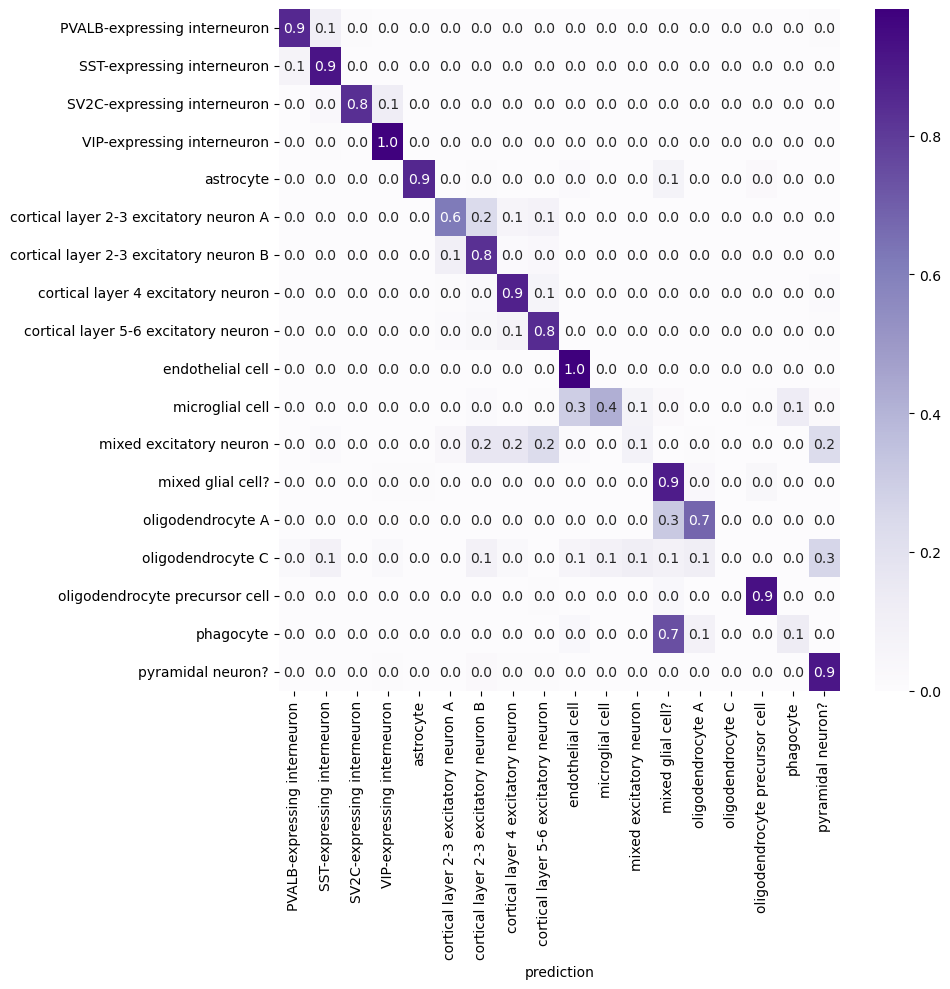

In [8]:
ref_job = get_job(32,20,10).index[0]
plt.figure(figsize=(10, 10))
sns.heatmap(results[ref_job]['cm'], annot=True, fmt=".1f", cmap="Purples")
plt.xlabel('prediction')
plt.tight_layout()
plt.savefig(experiment/f'results/confusion_matrix_{ref_job}.png')

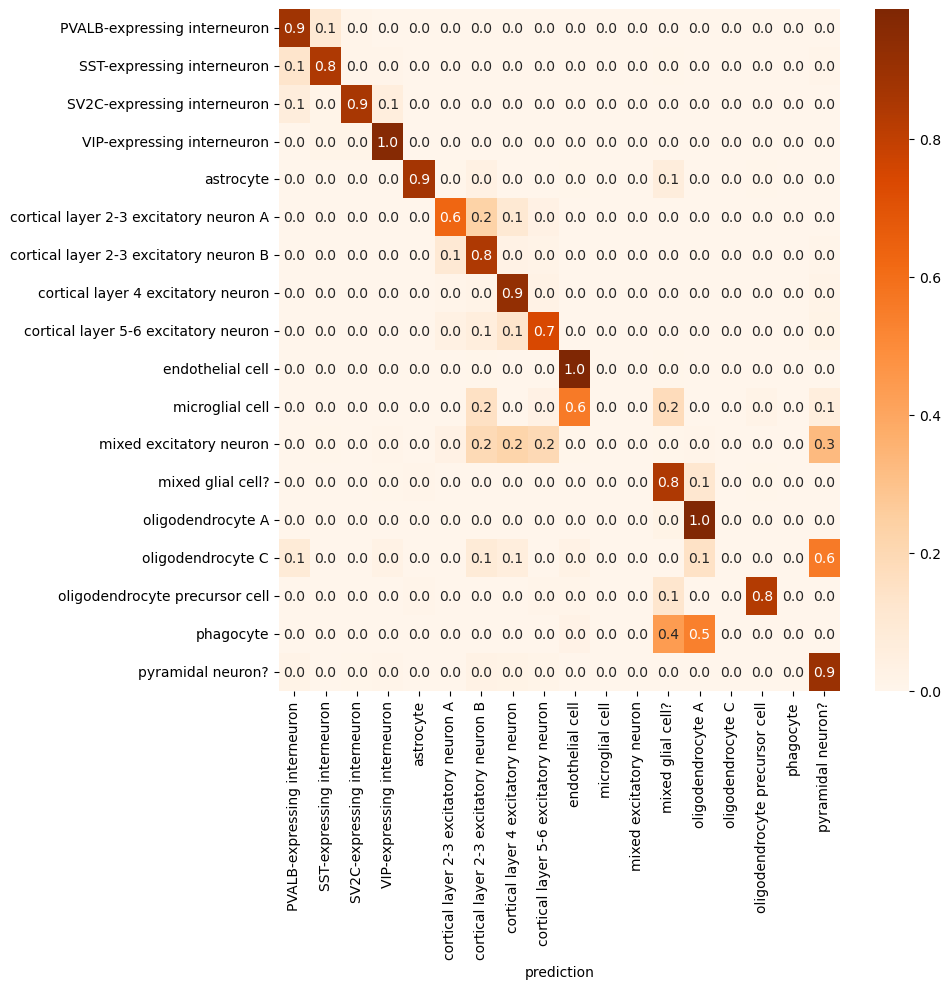

In [9]:
job = get_job(32,20,10).index[1]
plt.figure(figsize=(10, 10))
sns.heatmap(results[job]['cm'], annot=True, fmt=".1f", cmap="Oranges")
plt.xlabel('prediction')
plt.tight_layout()
plt.savefig(experiment/f'results/confusion_matrix_{job}.png')

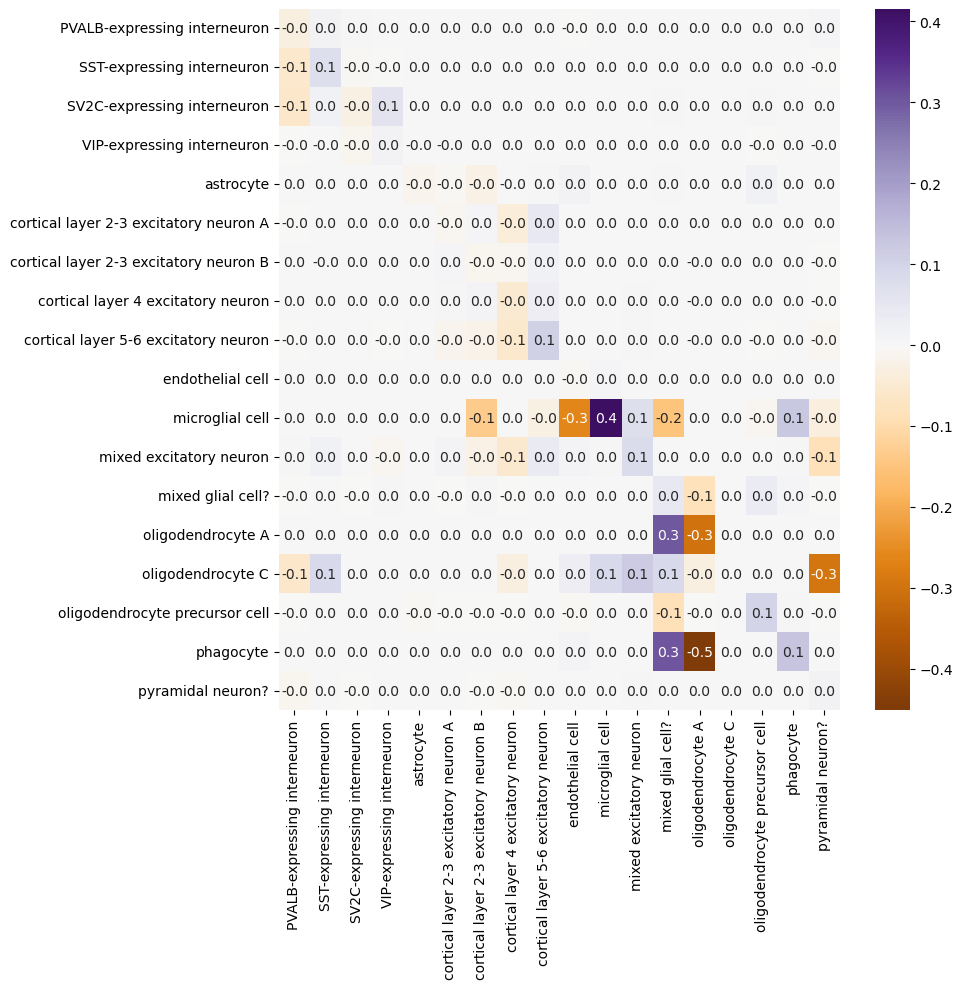

In [10]:
comp_job = get_job(32,20,10).index[1]
comp = results[ref_job]['cm'] - results[comp_job]['cm']
plt.figure(figsize=(10, 10))
sns.heatmap(comp, annot=True, fmt=".1f", cmap="PuOr", center=0)
plt.savefig(experiment/f'results/comparison_{ref_job}_{comp_job}.png')
plt.tight_layout()

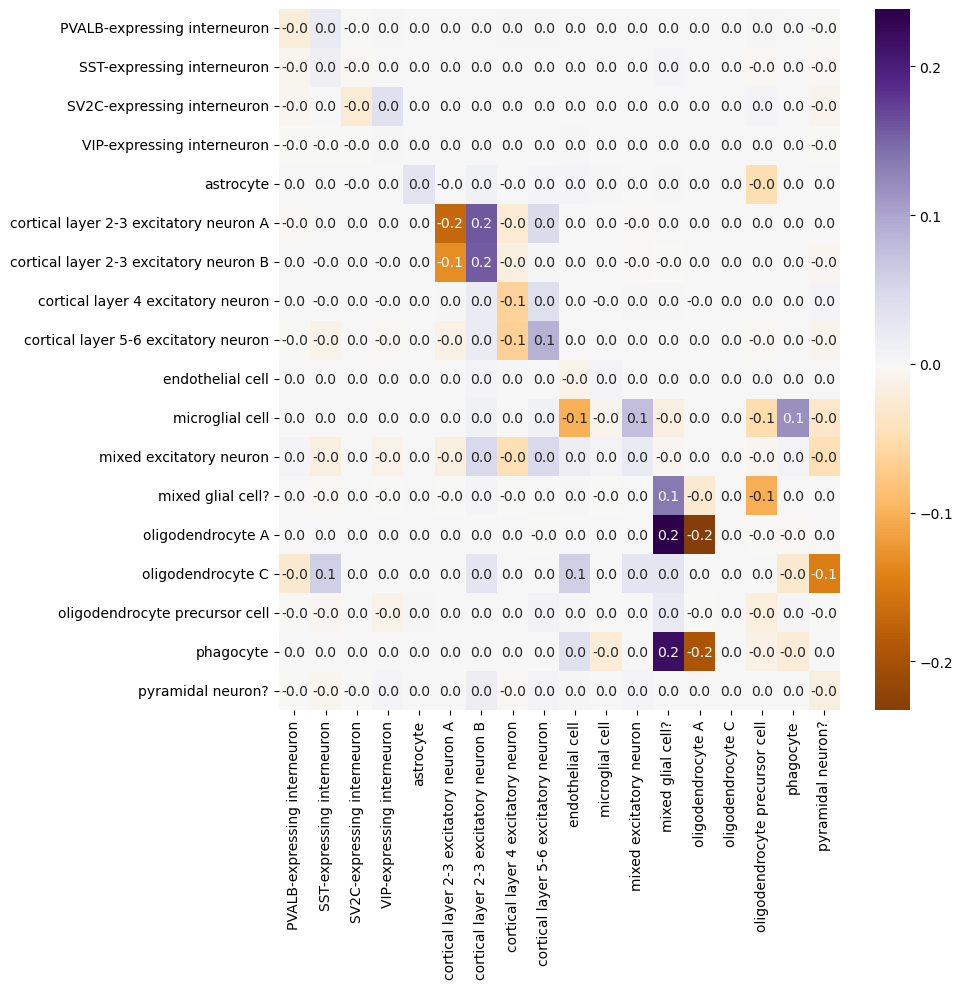

In [12]:
comp = results[ref_job]['cm'] - results[get_job(32,10,10).index[0]]['cm']
plt.figure(figsize=(10, 10))
sns.heatmap(comp, annot=True, fmt=".1f", cmap="PuOr", center=0)
plt.tight_layout()

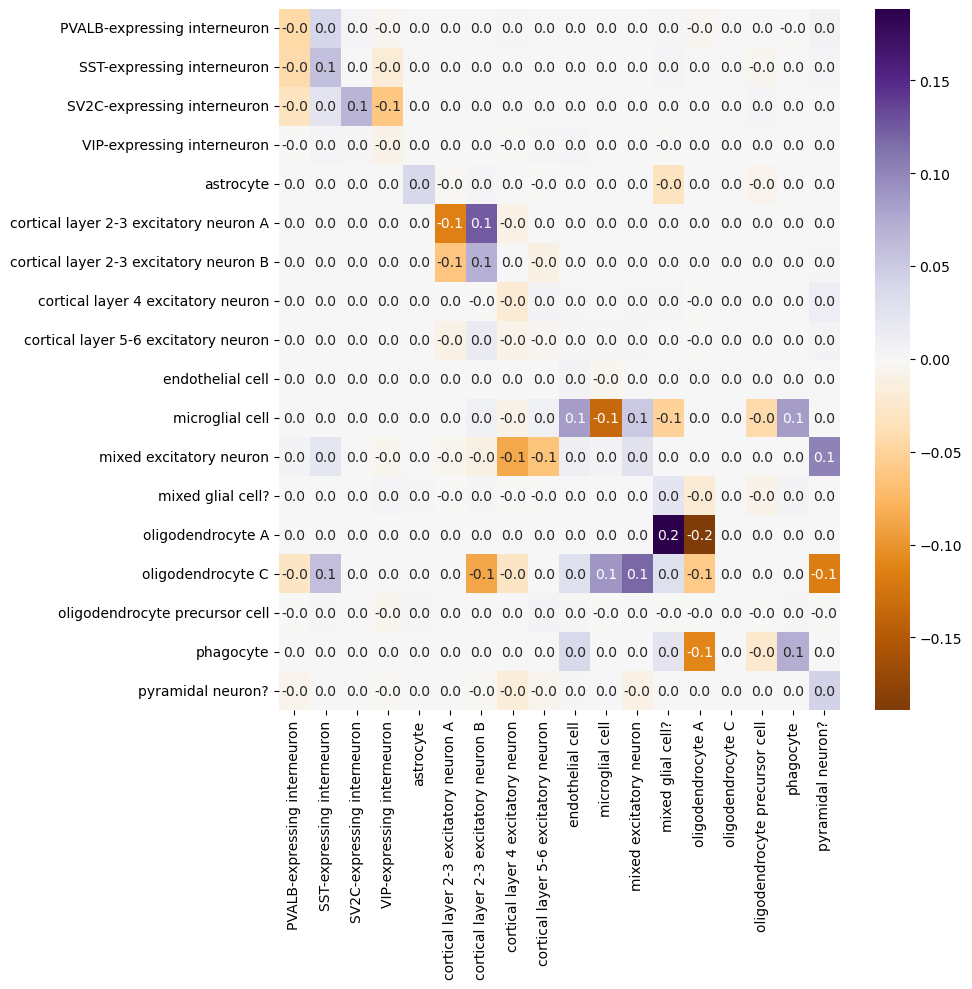

In [13]:
comp = results[ref_job]['cm'] - results[get_job(32,30,10).index[0]]['cm']
plt.figure(figsize=(10, 10))
sns.heatmap(comp, annot=True, fmt=".1f", cmap="PuOr", center=0)
plt.tight_layout()

In [11]:
all_recalls = {ct: [] for ct in celltypes}

for idx in results:
    cm = results[idx]['cm']  
    
    for ct in celltypes:
        recall = cm.loc[ct, ct]
        all_recalls[ct].append(recall)

recall_rate = {}
for ct in celltypes:
    recalls = np.array(all_recalls[ct])
    mean_recall = recalls.mean()
    std_recall = recalls.std()
    recall_rate[ct] = {'mean' : mean_recall, 'std': std_recall, 'values': recalls}
recall_rate = pd.DataFrame(recall_rate).T.sort_values('mean', ascending=True).reset_index(drop=False,names='celltype')

In [12]:
recall_rate

,celltype,mean,std,values
0,oligodendrocyte C,0.0,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,mixed excitatory neuron,0.044324,0.033998,"[0.05405405405405406, 0.043243243243243246, 0...."
2,phagocyte,0.053659,0.068813,"[0.06097560975609756, 0.012195121951219513, 0...."
3,microglial cell,0.270339,0.220679,"[0.5508474576271186, 0.05084745762711865, 0.0,..."
4,cortical layer 2-3 excitatory neuron A,0.703185,0.069465,"[0.732484076433121, 0.8152866242038217, 0.7133..."
5,SV2C-expressing interneuron,0.734593,0.093585,"[0.7674418604651163, 0.6947674418604651, 0.607..."
6,cortical layer 2-3 excitatory neuron B,0.779201,0.065776,"[0.7589531680440771, 0.702020202020202, 0.7112..."
7,cortical layer 5-6 excitatory neuron,0.795323,0.039293,"[0.8516166281755196, 0.8048498845265589, 0.737..."
8,mixed glial cell?,0.798429,0.086904,"[0.8691099476439791, 0.7626527050610821, 0.815..."
9,PVALB-expressing interneuron,0.859909,0.026774,"[0.89749430523918, 0.8177676537585421, 0.83257..."


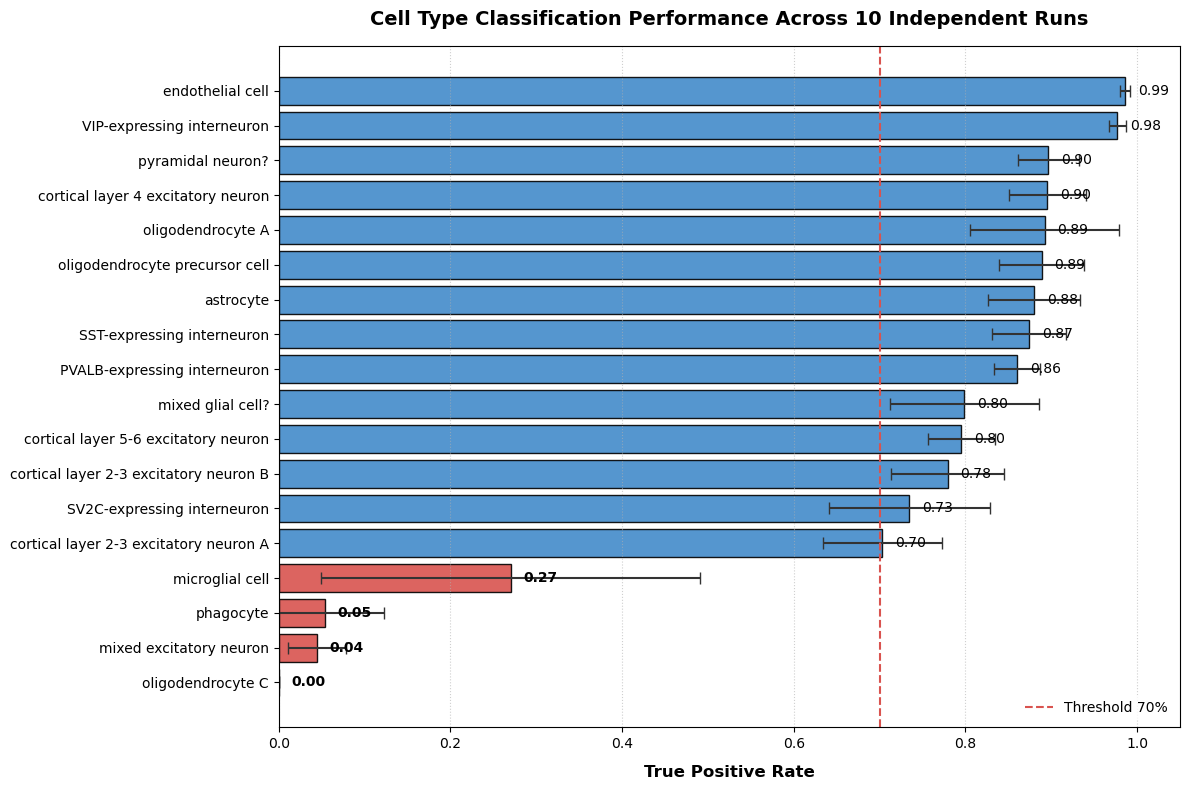

In [13]:
good_threshold = 0.7
bad_threshold = 0.5
colors = ['#d9534f' if x < bad_threshold else '#428bca' for x in recall_rate['mean']]
plt.figure(figsize=(12, 8))
bars = plt.barh(recall_rate['celltype'], recall_rate['mean'], xerr=recall_rate['std'], 
                color=colors, alpha=0.9, edgecolor='black', error_kw={'ecolor': '#333333', 'capsize': 4})
plt.axvline(good_threshold, color='#d9534f', linestyle='--', linewidth=1.5, label='Threshold 70%')
plt.xlim(0, 1.05)
plt.xlabel('True Positive Rate', fontsize=12, fontweight='bold', labelpad=10)
plt.title(f'Cell Type Classification Performance Across {len(results)} Independent Runs', fontsize=14, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle=':', alpha=0.6)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.015, bar.get_y() + bar.get_height()/2, f'{width:.2f}', 
             va='center', ha='left', fontsize=10, fontweight='bold' if width < 0.4 else 'normal')

plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.savefig(experiment/'results/true_positive_rate.png')
plt.show()


In [15]:
problem_cells = ['oligodendrocyte C', 'mixed excitatory neuron', 'phagocyte', 'microglial cell']

print("Top consistent misclassifications across all 8 runs:")
print("=" * 60)

for ct in problem_cells:
    # Gather the entire row for this cell type across all 8 jobs
    all_rows = []
    for idx in results:
        cm = results[idx]['cm']
        # Extract the row, drop the true positive diagonal to only look at errors
        row_errors = cm.loc[ct].drop(ct)
        all_rows.append(row_errors)
    
    # Average the errors across all runs
    mean_errors = pd.DataFrame(all_rows).mean(axis=0).sort_values(ascending=False)
    
    print(f"\nTrue Type: {ct.upper()}")
    print(f"  -> Commonly misclassified as:")
    for target, value in mean_errors.head(2).items():
        print(f"     - {target:<40} ({value*100:.1f}% of the time)")


Top consistent misclassifications across all 8 runs:

True Type: OLIGODENDROCYTE C
  -> Commonly misclassified as:
     - pyramidal neuron?                        (35.6% of the time)
     - cortical layer 2-3 excitatory neuron B   (13.6% of the time)

True Type: MIXED EXCITATORY NEURON
  -> Commonly misclassified as:
     - cortical layer 5-6 excitatory neuron     (23.2% of the time)
     - pyramidal neuron?                        (22.4% of the time)

True Type: PHAGOCYTE
  -> Commonly misclassified as:
     - mixed glial cell?                        (58.0% of the time)
     - oligodendrocyte A                        (31.9% of the time)

True Type: MICROGLIAL CELL
  -> Commonly misclassified as:
     - endothelial cell                         (42.4% of the time)
     - mixed glial cell?                        (7.4% of the time)


In [16]:
miscl = []
for ct in celltypes:
    all_rows = []
    for idx in results:
        cm = results[idx]['cm']
        row_errors = cm.loc[ct].copy(ct)
        row_errors[ct] = 0.0
        all_rows.append(row_errors)
    mean_errors = pd.DataFrame(all_rows).mean(axis=0)
    mean_errors.name = ct
    miscl.append(mean_errors)
miscl = pd.DataFrame(miscl)
miscl = miscl.fillna(0)

In [17]:
tp_threshold = 0.5
n = 3
problem_cells = recall_rate.query('mean < @tp_threshold').celltype.to_list()
miscl.T[problem_cells[0]].sort_values(ascending=False).head(n)

pyramidal neuron?                         0.355615
cortical layer 2-3 excitatory neuron B    0.136364
oligodendrocyte A                         0.128342
Name: oligodendrocyte C, dtype: float64

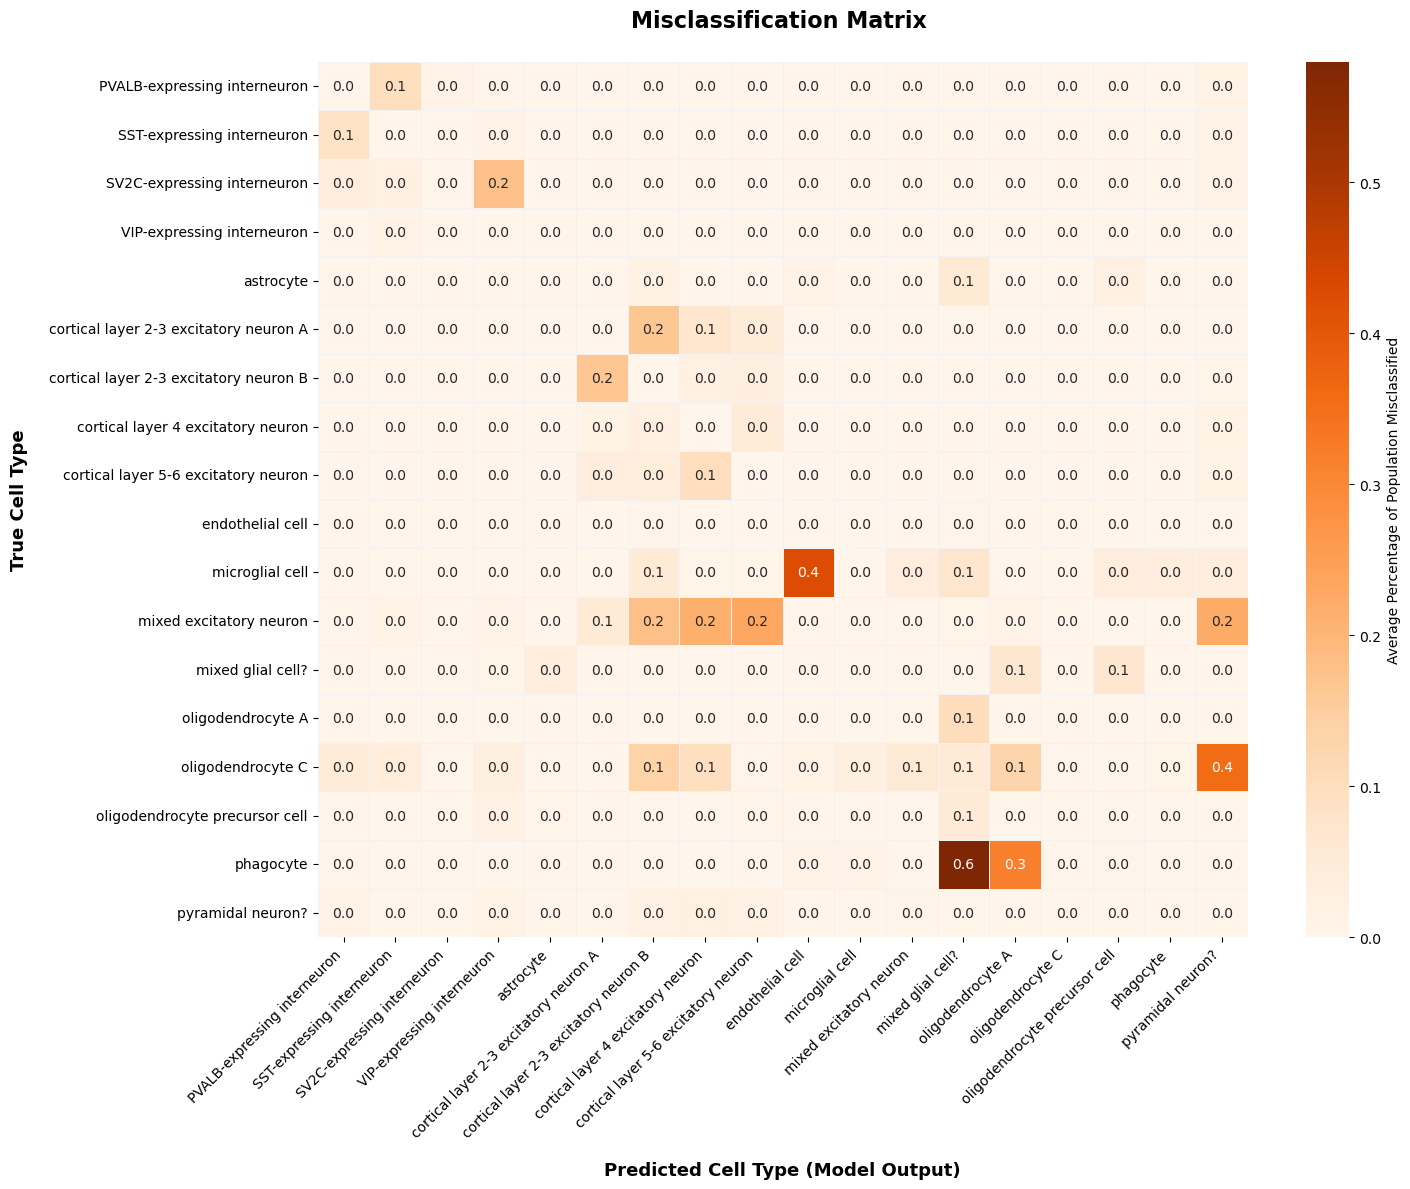

In [18]:
ordered_celltypes = [ct for ct in miscl.columns if ct in miscl.index]
miscl_symmetric = miscl.loc[ordered_celltypes, ordered_celltypes]

plt.figure(figsize=(15, 12))

ax = sns.heatmap(
    miscl_symmetric,
    annot=True,
    fmt=".1f",
    cmap="Oranges",
    linewidths=0.5,
    linecolor="#f2f2f2",
    cbar_kws={"label": "Average Percentage of Population Misclassified"},
)

plt.title(
    "Misclassification Matrix ",
    fontsize=16,
    weight="bold",
    pad=25,
)
plt.xlabel(
    "Predicted Cell Type (Model Output)", fontsize=13, weight="bold", labelpad=15
)
plt.ylabel("True Cell Type", fontsize=13, weight="bold", labelpad=15)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.savefig(experiment/'results/misclassification_matrix.png')
plt.show()
